<a href="https://colab.research.google.com/github/nasy-sr/artificial-intelligence-coursework-2024-genap/blob/main/uas_heart_disease_classification_nb_knn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project UAS AI - Heart Disease Prediction atau Prediksi Penyakit Jantung**

**Nama:** Nasywa Salsabiila Romadhona

**Kelas:** Sistem Informasi 2A

In [ ]:
# Pemasangan Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Bagian ini digunakan untuk mengimpor semua library dan modul yang diperlukan untuk analisis data dan implementasi model machine learning.
import pandas as pd # pandas: untuk manipulasi data (DataFrame)
import numpy as np # numpy: untuk operasi numerik
import matplotlib.pyplot as plt # matplotlib & seaborn: untuk visualisasi data
import seaborn as sns
from sklearn.model_selection import train_test_split # sklearn: untuk model machine learning dan metrik evaluasi
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, cohen_kappa_score, recall_score
from warnings import filterwarnings # warnings: untuk mengabaikan peringatan yang mungkin muncul
filterwarnings('ignore')

## B. Preprocessing Dataset

In [ ]:
# Jalur (path) ke file CSV di Google Drive
file_path = '/content/drive/MyDrive/Colab Notebooks/UAS ARTIFICIAL INTELLIGENCE/processed.cleveland.data'

In [ ]:
# Pemuatan dan pemahaman data, untuk mendefinisikan nama kolom berdasarkan dataset UCI Heart Disease atau Penyakit Jantung
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']

In [ ]:
# Bagian ini memuat dataset dari file CSV yang telah ditentukan dan melakukan pemeriksaan awal terhadap struktur data.

df = pd.read_csv(file_path, header=None, names=columns, na_values='?')

print("Informasi Dataset:")
df.info()

print("\nLima baris pertama dari dataset:")
print(df.head())

Informasi Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Lima baris pertama dari dataset:
    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0

In [ ]:
# Bagian ini melakukan penanganan nilai yang hilang (missing values).
print("\nJumlah missing values sebelum penanganan:")
print(df.isnull().sum())


Jumlah missing values sebelum penanganan:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64


In [ ]:
# Menghapus baris dengan nilai yang hilang karena jumlahnya sedikit
df.dropna(inplace=True)

print("\nJumlah missing values setelah penanganan:")
print(df.isnull().sum())
print("\nInformasi Dataset setelah pembersihan:")
df.info()


Jumlah missing values setelah penanganan:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64

Informasi Dataset setelah pembersihan:
<class 'pandas.core.frame.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  num       297 non-

In [ ]:
# Normalisasi atau scaling (khusus untuk KNN) & Encoding variabel kategorikal
# Dataset ini memiliki nilai numerik, tetapi beberapa di antaranya bersifat kategoris. Kolom `num` adalah targetnya.
# Mengubah variabel target menjadi biner (0 = tidak ada penyakit, 1 = penyakit)
df['num'] = df['num'].apply(lambda x: 1 if x > 0 else 0)
print("\nDistribusi kelas target (num):")
print(df['num'].value_counts())


Distribusi kelas target (num):
num
0    160
1    137
Name: count, dtype: int64


## C. Implementasi Algoritma (Naive Bayes & KNN)

In [ ]:
# Definisikan fitur (X) dan target (y)
X = df.drop('num', axis=1)
y = df['num']

In [ ]:
# Definisikan rasio split yang akan digunakan
split_ratios = [(0.6, 0.4), (0.7, 0.3), (0.8, 0.2)]


--- Menggunakan rasio split Train:60% Test:40% ---


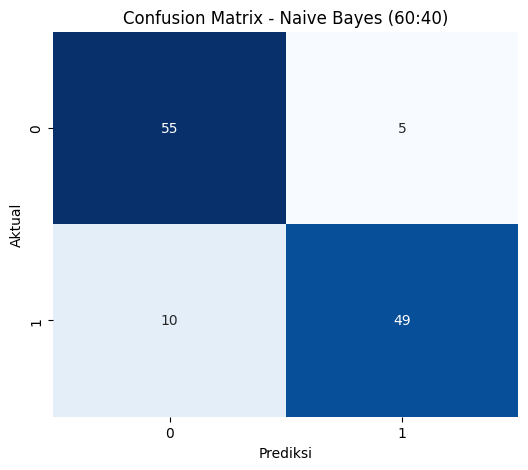


Visualisasi Confusion Matrix untuk KNN (60:40)


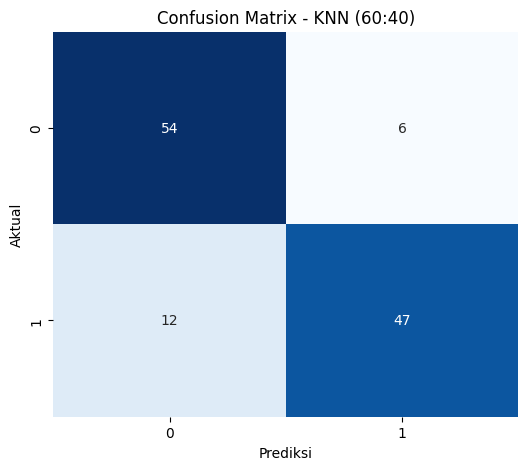


--- Menggunakan rasio split Train:70% Test:30% ---


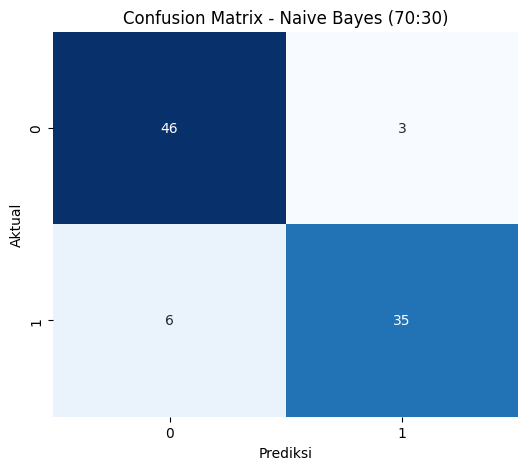


Visualisasi Confusion Matrix untuk KNN (70:30)


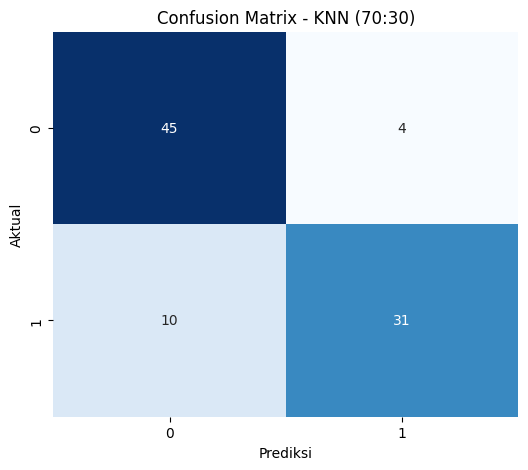


--- Menggunakan rasio split Train:80% Test:20% ---


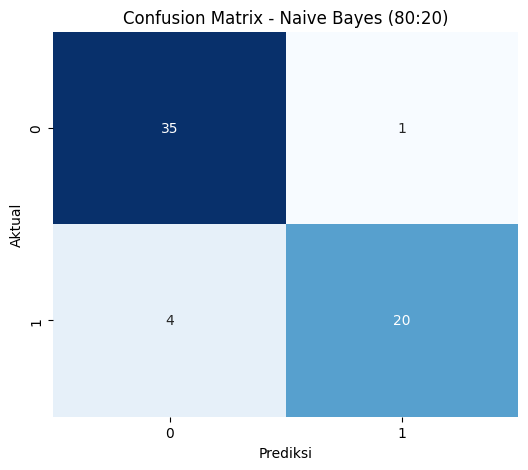


Visualisasi Confusion Matrix untuk KNN (80:20)


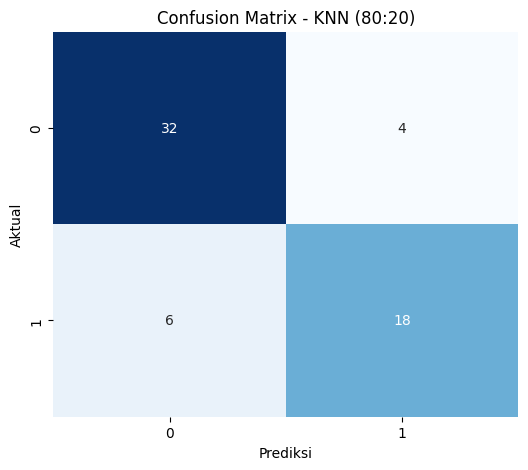

In [ ]:
results = []

# Function to calculate specificity
def calculate_specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

for train_ratio, test_ratio in split_ratios:
    print(f"\n--- Menggunakan rasio split Train:{int(train_ratio*100)}% Test:{int(test_ratio*100)}% ---")

    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_ratio, random_state=42)

    # Scaling data for KNN
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Implementasi Naive Bayes
    gnb = GaussianNB()
    gnb.fit(X_train, y_train)
    y_pred_gnb = gnb.predict(X_test)

    # Implementasi KNN
    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(X_train_scaled, y_train)
    y_pred_knn = knn.predict(X_test_scaled)

    # Perhitungan metrik untuk Naive Bayes
    accuracy_gnb = accuracy_score(y_test, y_pred_gnb)
    sensitivity_gnb = recall_score(y_test, y_pred_gnb)
    specificity_gnb = calculate_specificity(y_test, y_pred_gnb)
    kappa_gnb = cohen_kappa_score(y_test, y_pred_gnb)

    # Perhitungan metrik untuk KNN
    accuracy_knn = accuracy_score(y_test, y_pred_knn)
    sensitivity_knn = recall_score(y_test, y_pred_knn)
    specificity_knn = calculate_specificity(y_test, y_pred_knn)
    kappa_knn = cohen_kappa_score(y_test, y_pred_knn)

    results.append({
        'Split Ratio': f'{int(train_ratio*100)}:{int(test_ratio*100)}',
        'Model': 'Naive Bayes',
        'Accuracy': accuracy_gnb,
        'Sensitivity': sensitivity_gnb,
        'Specificity': specificity_gnb,
        'Kappa': kappa_gnb
    })
    results.append({
        'Split Ratio': f'{int(train_ratio*100)}:{int(test_ratio*100)}',
        'Model': 'KNN',
        'Accuracy': accuracy_knn,
        'Sensitivity': sensitivity_knn,
        'Specificity': specificity_knn,
        'Kappa': kappa_knn
    })

    # Visualisasi Confusion Matrix untuk Naive Bayes pada setiap iterasi
    cm_gnb = confusion_matrix(y_test, y_pred_gnb)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_gnb, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - Naive Bayes ({int(train_ratio*100)}:{int(test_ratio*100)})')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.show()

    # Visualisasi Confusion Matrix untuk KNN pada setiap iterasi
    print(f"\nVisualisasi Confusion Matrix untuk KNN ({int(train_ratio*100)}:{int(test_ratio*100)})")
    cm_knn = confusion_matrix(y_test, y_pred_knn)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_knn, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'Confusion Matrix - KNN ({int(train_ratio*100)}:{int(test_ratio*100)})')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.show()

## D. Evaluasi Performa Model

In [ ]:
# Menampilkan hasil dalam DataFrame setelah loop selesai
results_df = pd.DataFrame(results)
print("\nPerbandingan Performa Model:")
print(results_df.round(4))


Perbandingan Performa Model:
  Split Ratio        Model  Accuracy  Sensitivity  Specificity   Kappa
0       60:40  Naive Bayes    0.8739       0.8305       0.9167  0.7477
1       60:40          KNN    0.8487       0.7966       0.9000  0.6972
2       70:30  Naive Bayes    0.9000       0.8537       0.9388  0.7972
3       70:30          KNN    0.8444       0.7561       0.9184  0.6826
4       80:20  Naive Bayes    0.9167       0.8333       0.9722  0.8227
5       80:20          KNN    0.8333       0.7500       0.8889  0.6479


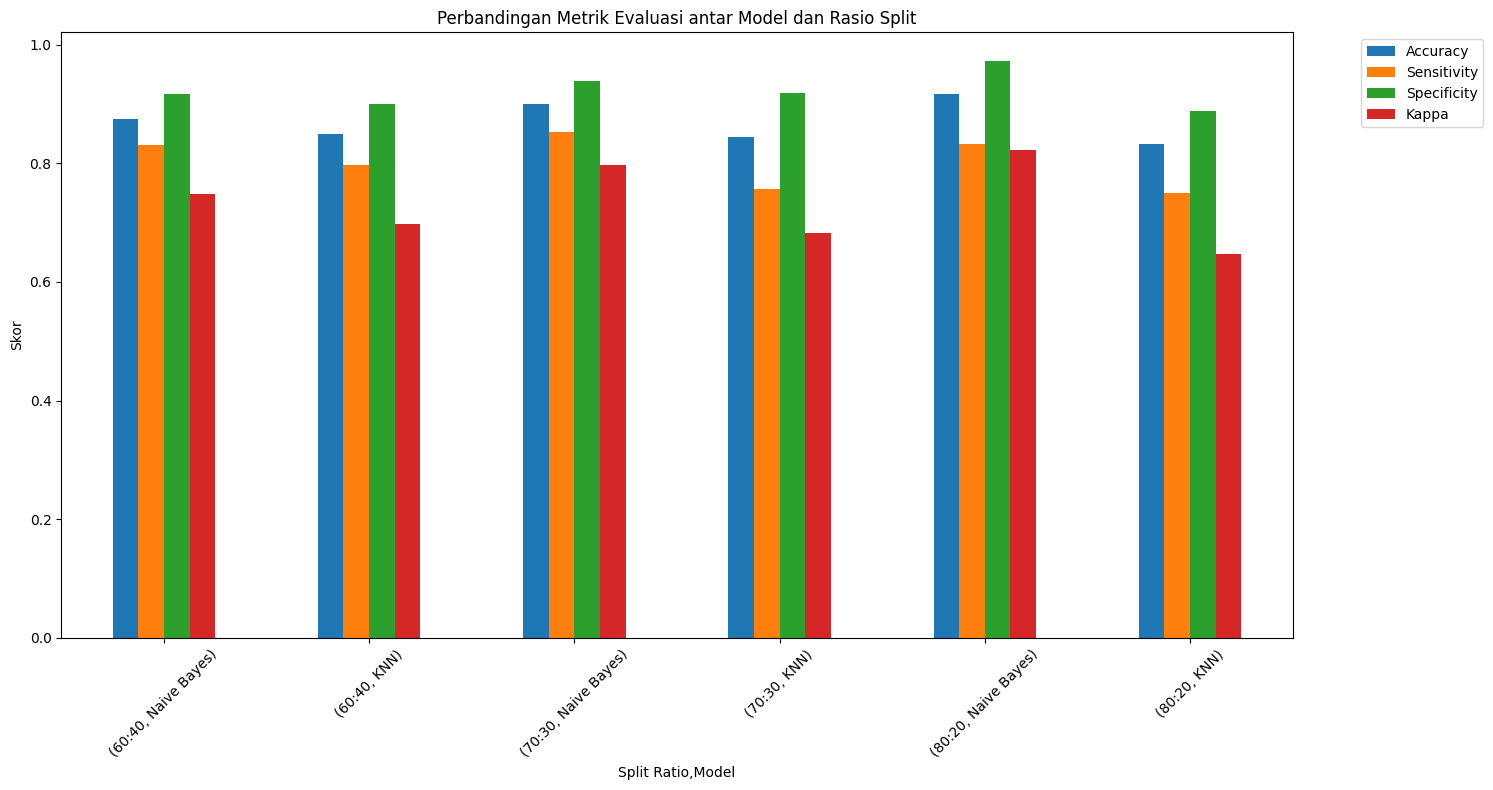

In [ ]:
# Visualisasi perbandingan metrik dari semua model dan rasio split
results_df.set_index(['Split Ratio', 'Model']).plot(kind='bar', figsize=(15, 8))
plt.title('Perbandingan Metrik Evaluasi antar Model dan Rasio Split')
plt.ylabel('Skor')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## E. Visualisasi & Eksplorasi Data

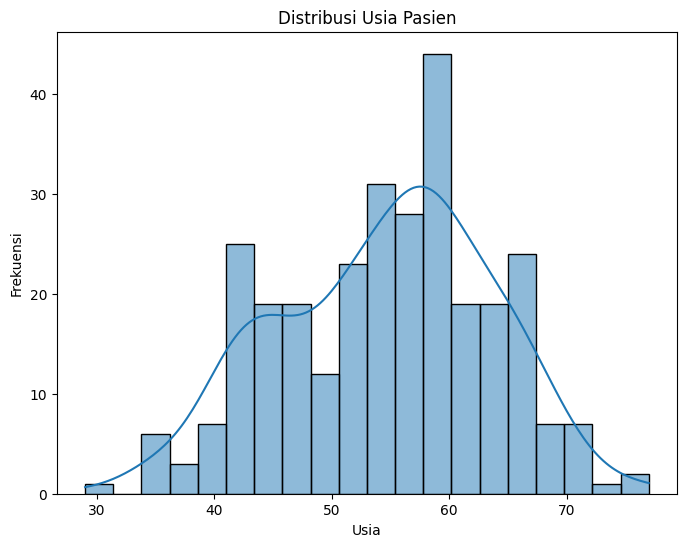

In [ ]:
# Histogram Usia Pasien
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.histplot(df['age'], bins=20, kde=True)
plt.title('Distribusi Usia Pasien')
plt.xlabel('Usia')
plt.ylabel('Frekuensi')
plt.savefig('age_distribution.png')
plt.show()

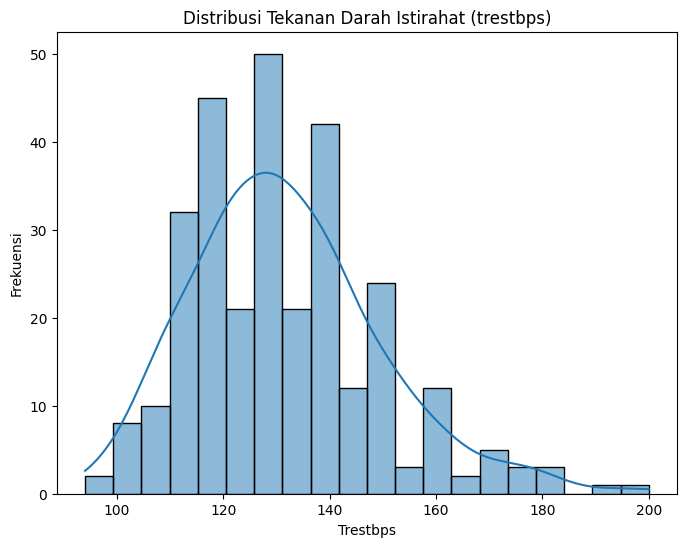

In [ ]:
# Histogram untuk Tekanan Darah Istirahat Pasien
plt.figure(figsize=(8, 6))
sns.histplot(df['trestbps'], bins=20, kde=True)
plt.title('Distribusi Tekanan Darah Istirahat (trestbps)')
plt.xlabel('Trestbps')
plt.ylabel('Frekuensi')
plt.show()

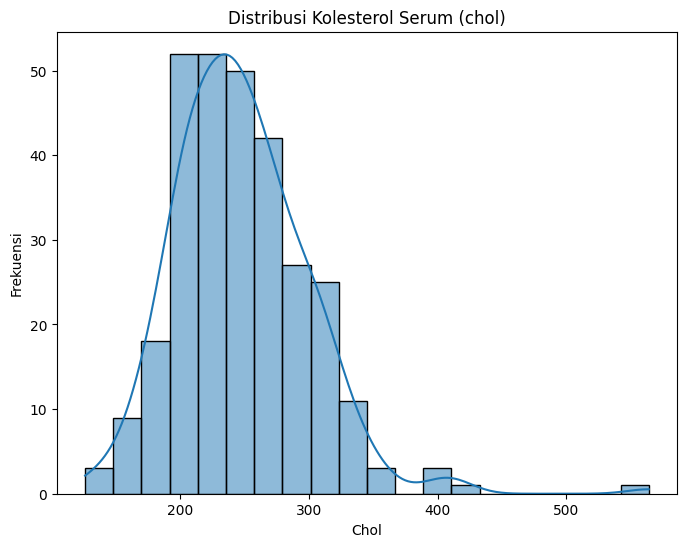

In [ ]:
# Histogram untuk Kolestrol Serum Pasien
plt.figure(figsize=(8, 6))
sns.histplot(df['chol'], bins=20, kde=True)
plt.title('Distribusi Kolesterol Serum (chol)')
plt.xlabel('Chol')
plt.ylabel('Frekuensi')
plt.show()

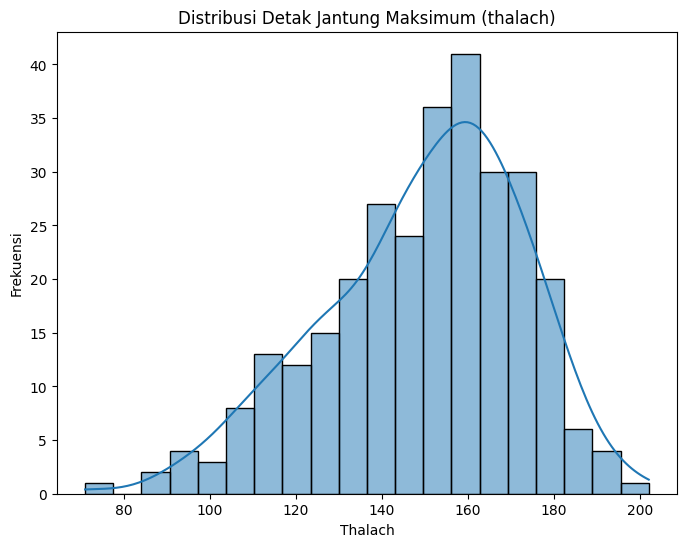

In [ ]:
# Histogram untuk Detak Jantung Maksimum Pasien
plt.figure(figsize=(8, 6))
sns.histplot(df['thalach'], bins=20, kde=True)
plt.title('Distribusi Detak Jantung Maksimum (thalach)')
plt.xlabel('Thalach')
plt.ylabel('Frekuensi')
plt.show()

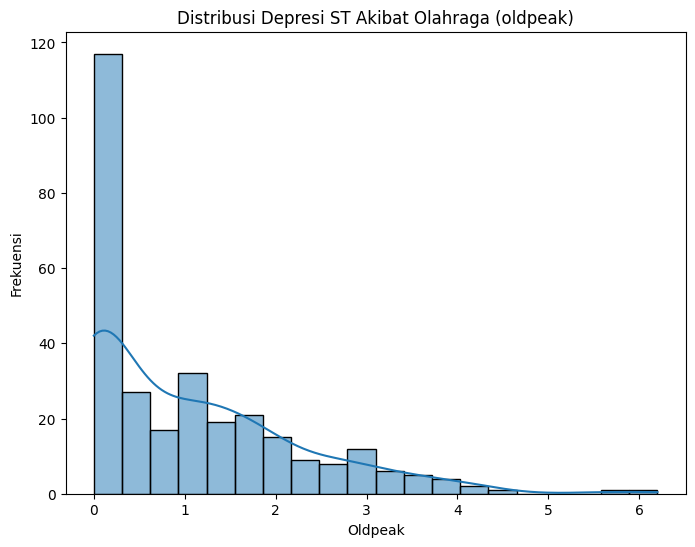

In [ ]:
# Histogram untuk Depresi ST Akibat Olahraga Pasien
plt.figure(figsize=(8, 6))
sns.histplot(df['oldpeak'], bins=20, kde=True)
plt.title('Distribusi Depresi ST Akibat Olahraga (oldpeak)')
plt.xlabel('Oldpeak')
plt.ylabel('Frekuensi')
plt.show()

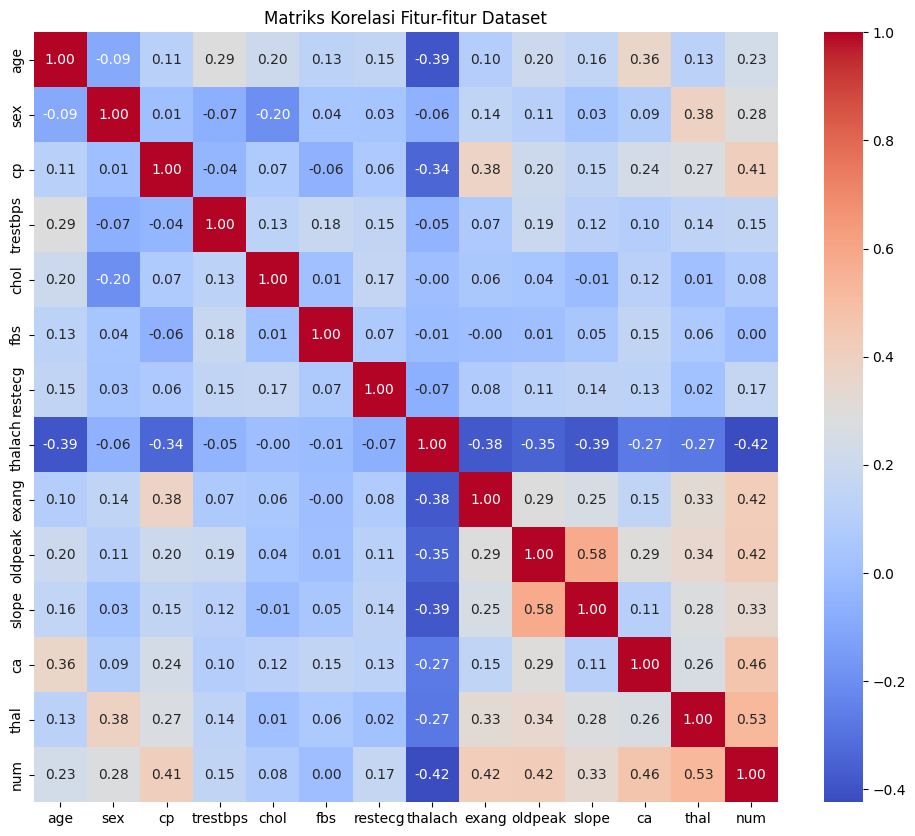

In [ ]:
# Matriks Korelasi Fitur-Fitur Dataset
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Fitur-fitur Dataset')
plt.savefig('correlation_heatmap.png')
plt.show()

### Interpretasi Hasil Evaluasi

Berdasarkan perbandingan performa model di atas, dapat diinterpretasikan sebagai berikut:

* **Perbandingan Model:** Model Naive Bayes secara konsisten menunjukkan performa yang lebih baik dibandingkan dengan model KNN di semua metrik evaluasi (Akurasi, Sensitivitas, Spesifisitas, dan Kappa) dan pada semua rasio split yang diuji.
* **Akurasi:** Akurasi tertinggi dicapai oleh model Naive Bayes pada rasio split 80:20, dengan nilai 0.9167. Akurasi KNN juga lebih rendah pada setiap rasio.
* **Kemampuan Deteksi:** Naive Bayes memiliki nilai Sensitivitas (kemampuan mendeteksi kasus penyakit) dan Spesifisitas (kemampuan mendeteksi kasus sehat) yang lebih tinggi, terutama pada rasio 80:20.
* **Skor Kappa:** Skor Kappa Cohen Naive Bayes selalu lebih tinggi dari KNN, menunjukkan tingkat kesepakatan yang lebih baik antara prediksi dan nilai aktual di luar faktor kebetulan.
* **Pengaruh Rasio Split:** Untuk kedua model, performa terbaik cenderung tercapai saat menggunakan rasio split 80:20, yang mana model dilatih dengan data yang lebih banyak.

### Kesimpulan

Berdasarkan seluruh tahapan analisis dan evaluasi yang telah dilakukan,
dapat disimpulkan bahwa model **Naive Bayes** adalah pilihan yang lebih unggul untuk memprediksi penyakit jantung pada dataset ini. Model ini secara konsisten memberikan nilai Akurasi, Sensitivitas, Spesifisitas, dan Kappa yang lebih tinggi dibandingkan dengan model KNN. Rasio split data **80:20** terbukti menghasilkan performa terbaik untuk model Naive Bayes, menunjukkan pentingnya jumlah data pelatihan yang memadai untuk mendapatkan hasil prediksi yang optimal.